   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

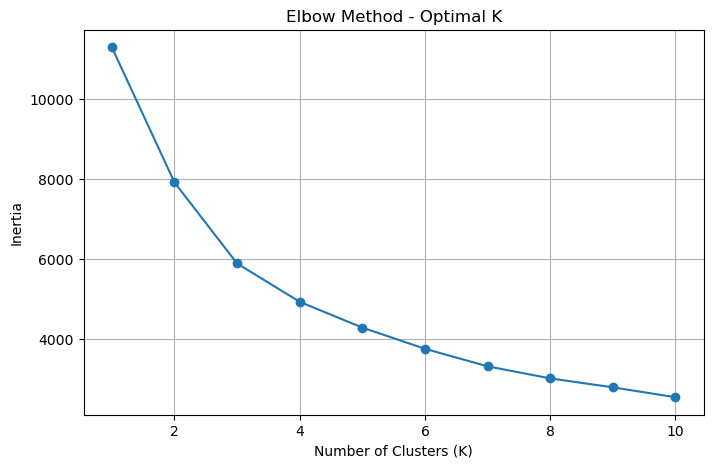

Cluster Centers:
[[-0.70854061  0.46259617 -0.26929189  0.82525847]
 [-0.43685254  0.41359923 -0.13496959 -1.01228217]
 [ 1.01181348  0.67408353  1.27088991  0.22337467]
 [ 0.04001807 -1.44645947 -0.87598836  0.05091556]]


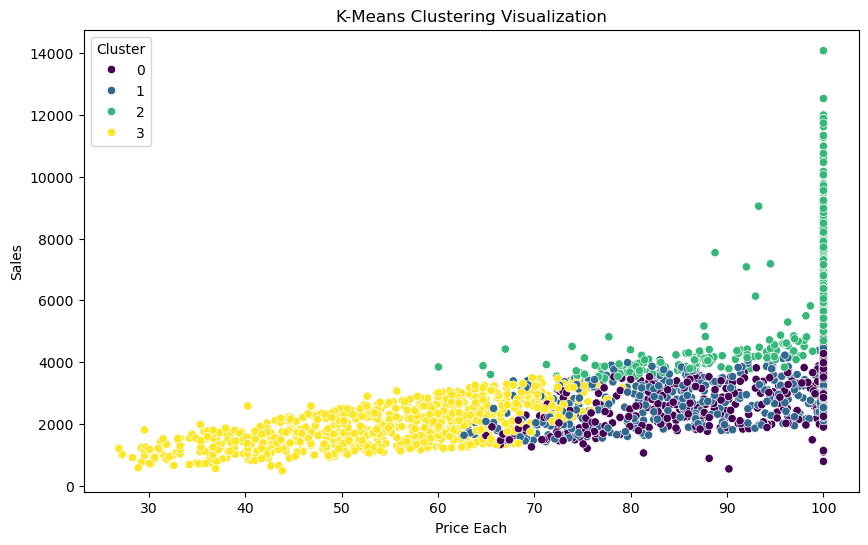

Cluster Summary:
               SALES  PRICEEACH  QUANTITYORDERED
Cluster                                         
0        3056.839670  93.000440        28.183673
1        3304.355601  91.949036        30.842179
2        5894.282221  97.255283        44.947586
3        1941.139275  54.471409        35.495302


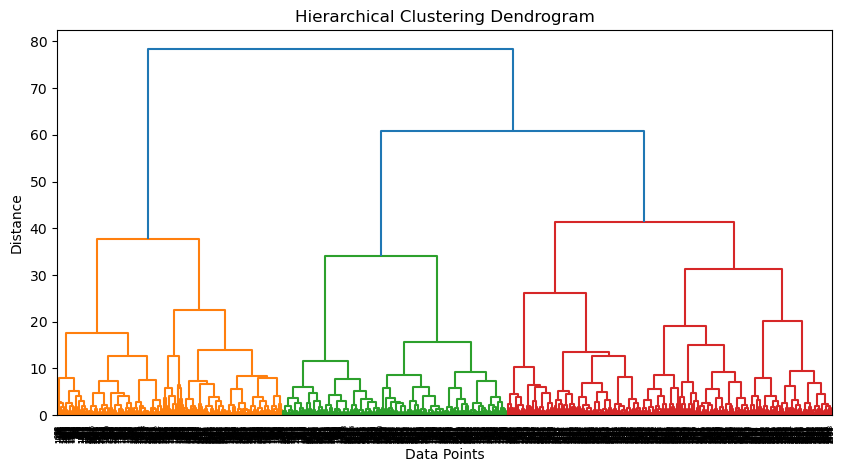

Hierarchical Cluster:
Hierarchical_Cluster
1    822
2    819
4    694
3    488
Name: count, dtype: int64


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Load dataset
df = pd.read_csv("sales.csv", encoding="unicode_escape")

# Display first 5 rows
print(df.head())
# Select numerical features
df_clean = df.select_dtypes(include=[np.number]).dropna()

# Select important features
features = df_clean[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'ORDERNUMBER']]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Elbow Method
inertia = []
K = range(1, 11)

for k in K:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker='o')
plt.title("Elbow Method - Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# Choose K = 4 based on elbow
kmeans = KMeans(n_clusters=4, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display cluster centers
print("Cluster Centers:")
print(kmeans.cluster_centers_)

# K-Means visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PRICEEACH',
    y='SALES',
    hue='Cluster',
    data=df,
    palette='viridis'
)

plt.title("K-Means Clustering Visualization")
plt.xlabel("Price Each")
plt.ylabel("Sales")
plt.legend(title="Cluster")
plt.show()

# Cluster summary
cluster_summary = df.groupby('Cluster')[
    ['SALES', 'PRICEEACH', 'QUANTITYORDERED']
].mean()

print("Cluster Summary:")
print(cluster_summary)

# Hierarchical Clustering
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# Create 4 hierarchical clusters
hierarchical_clusters = fcluster(
    Z,
    t=4,
    criterion='maxclust'
)

df['Hierarchical_Cluster'] = hierarchical_clusters

print("Hierarchical Cluster:")
print(df['Hierarchical_Cluster'].value_counts())